# TD4 Vision Par Ordinateur : Histogrammes des images

In [19]:
import cv2, numpy as np, matplotlib.pyplot as plt

## Exercice 1

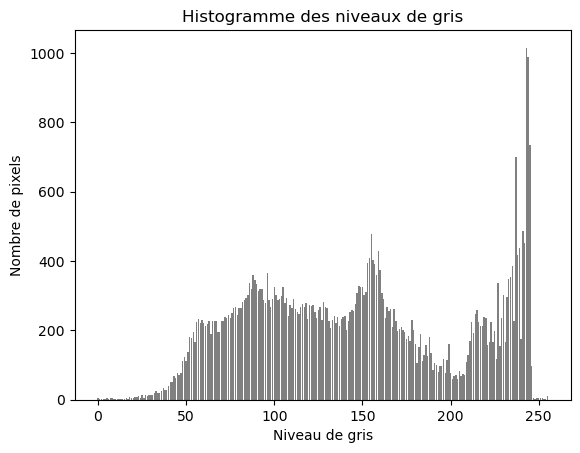

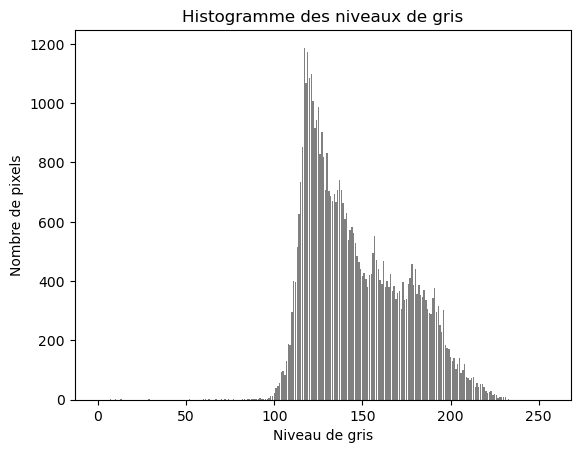

In [20]:
def histogramme(path,ng):
    img = cv2.imread(path,cv2.IMREAD_GRAYSCALE)
    rows, cols = img.shape
    count = 0
    for i in range(rows):
        for j in range(cols):
            if(img[i,j]==ng):
                count+=1
    return count
def tracerHistogramme(path):
    hist_values = [histogramme(path, ng) for ng in range(256)]
    plt.figure()
    plt.bar(range(256), hist_values, color='gray')
    plt.title("Histogramme des niveaux de gris")
    plt.xlabel("Niveau de gris")
    plt.ylabel("Nombre de pixels")
    plt.show()

tracerHistogramme("surexp.jpg")
tracerHistogramme("sousexpo1.jpg")

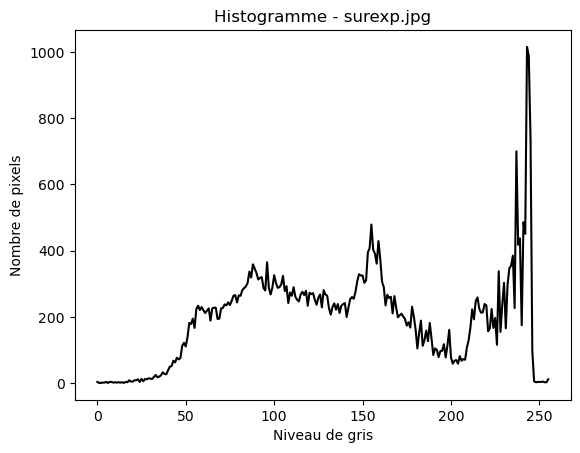

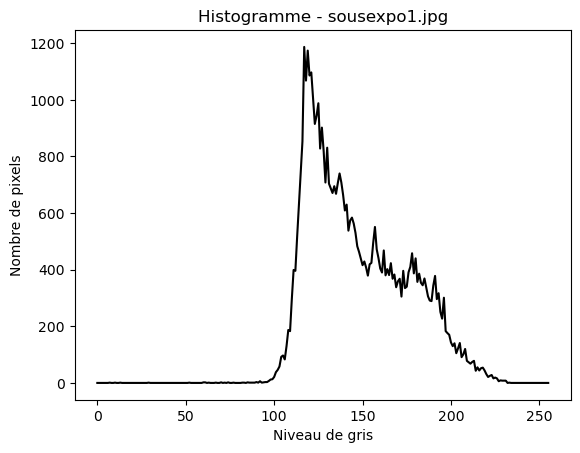

In [21]:
images = ["surexp.jpg", "sousexpo1.jpg"]

for path in images:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    hist = cv2.calcHist([img], [0], None, [256], [0, 256])
    
    plt.figure()
    plt.plot(hist, color='black')
    plt.title(f"Histogramme - {path}")
    plt.xlabel("Niveau de gris")
    plt.ylabel("Nombre de pixels")
    plt.show()

In [22]:
img = cv2.imread('sousexpo1.jpg')
print(np.min(img), np.max(img), end="  ")

5 235  

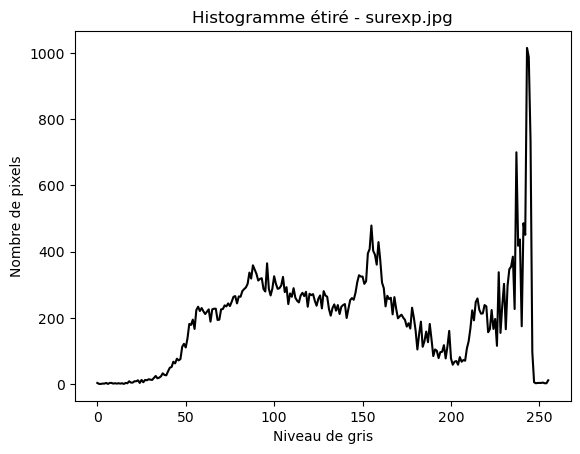

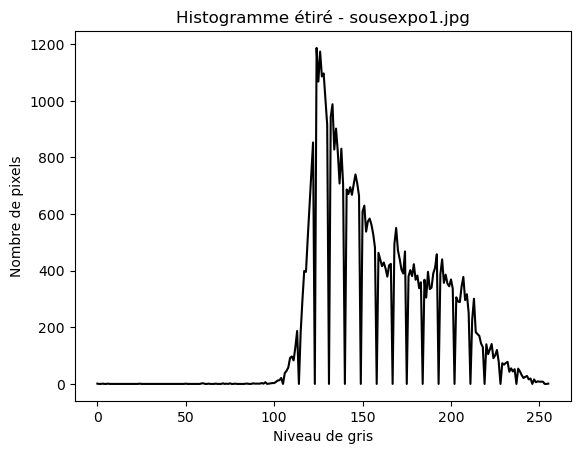

In [23]:
def etirer(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    Imin = np.min(img)
    Imax = np.max(img)
    # print(Imin,Imax,end='\n')
    # print(img)
    img_float = img.astype(np.float32)
    img_etiree = (255*(img_float - Imin)/(Imax - Imin)).astype(np.uint8)
    # print(img_etiree)
    hist = cv2.calcHist([img_etiree], [0], None, [256], [0, 256])
    plt.figure()
    plt.plot(np.arange(256), hist[:,0], color='black') 
    plt.title(f"Histogramme étiré - {path}")
    plt.xlabel("Niveau de gris")
    plt.ylabel("Nombre de pixels")
    plt.show()

etirer("surexp.jpg")
etirer("sousexpo1.jpg")

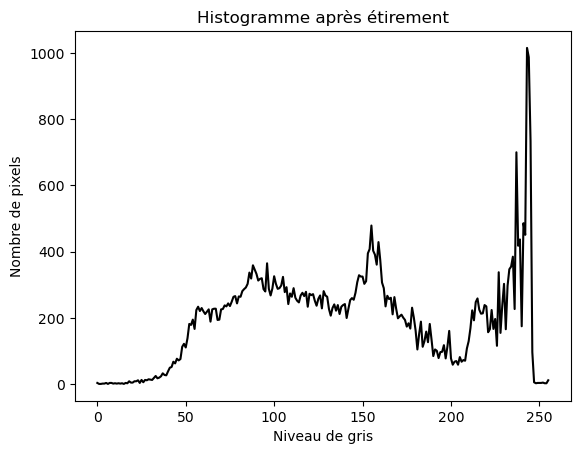

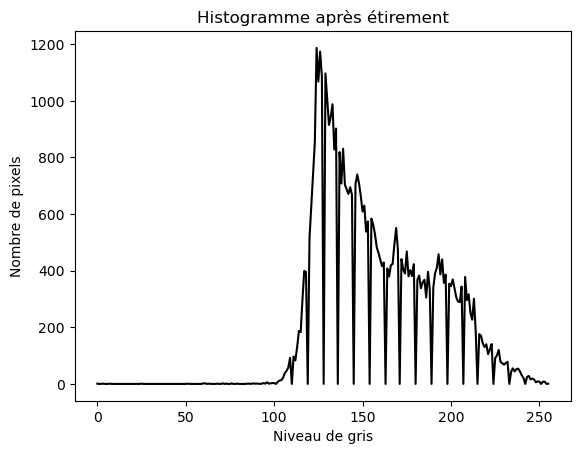

In [24]:
def etirer(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img_etiree = cv2.normalize(img, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    hist_etiree = cv2.calcHist([img_etiree], [0], None, [256], [0, 256])

    plt.figure()
    plt.plot(np.arange(256), hist_etiree[:,0], color='black')
    plt.title("Histogramme après étirement")
    plt.xlabel("Niveau de gris")
    plt.ylabel("Nombre de pixels")
    plt.show()

etirer('surexp.jpg')
etirer('sousexpo1.jpg')

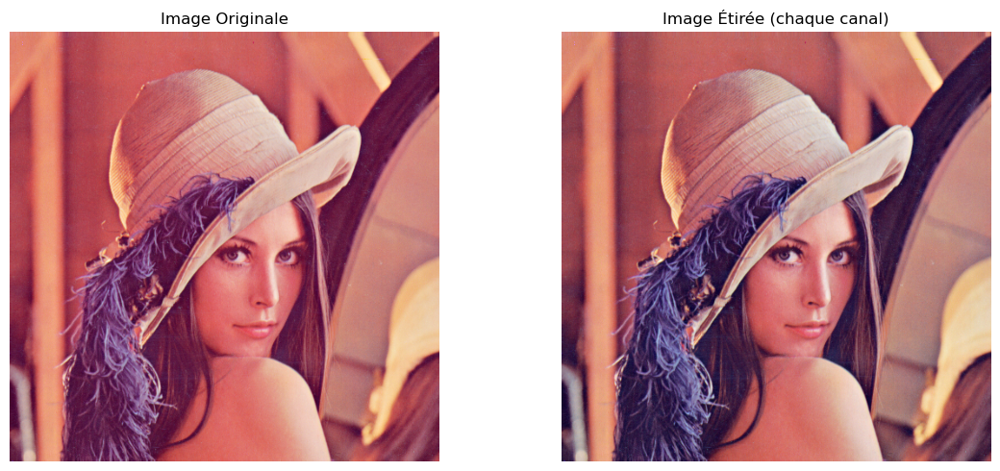

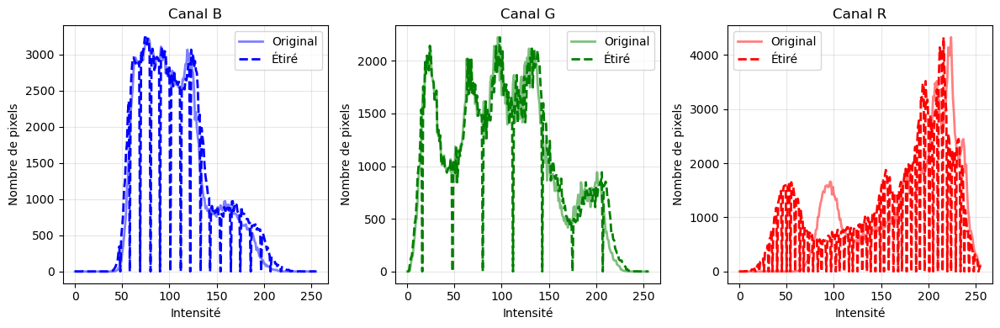

In [25]:
# Étirement d'une image couleur - Méthode : Étirer chaque canal séparément


img = cv2.imread('Images_TD1\lena.png', cv2.IMREAD_UNCHANGED)
b, g, r = cv2.split(img)

# Étirer chaque canal individuellement entre 0 et 255
# cv2.normalize applique la formule: pixel_etiré = (pixel - min) * (beta - alpha) / (max - min) + alpha
b_etire = cv2.normalize(b, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
g_etire = cv2.normalize(g, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
r_etire = cv2.normalize(r, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)

# Fusionner les canaux étirés pour reconstruire l'image couleur
img_etiree = cv2.merge([b_etire, g_etire, r_etire])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Image Originale")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img_etiree, cv2.COLOR_BGR2RGB))
axes[1].set_title("Image Étirée (chaque canal)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

colors = ('b', 'g', 'r')
plt.figure(figsize=(12, 4))

for i, color in enumerate(colors):
    plt.subplot(1, 3, i+1)
    hist_original = cv2.calcHist([img], [i], None, [256], [0, 256])
    hist_etire = cv2.calcHist([img_etiree], [i], None, [256], [0, 256])
    
    plt.plot(hist_original, color=color, alpha=0.5, label='Original', linewidth=2)
    plt.plot(hist_etire, color=color, linestyle='--', label='Étiré', linewidth=2)
    plt.title(f'Canal {color.upper()}')
    plt.xlabel('Intensité')
    plt.ylabel('Nombre de pixels')
    plt.legend()
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Étirement Manuel

L'étirement d'histogramme applique la formule suivante pour chaque canal :

$$I_{étiré} = \frac{(I - I_{min}) \times 255}{I_{max} - I_{min}}$$

où :
- $I$ = intensité du pixel original
- $I_{min}$ = valeur minimale du canal
- $I_{max}$ = valeur maximale du canal


Canal Bleu:
Min: 8, Max: 239
Canal Vert:
Min: 1, Max: 248
Canal Rouge:
Min: 54, Max: 255


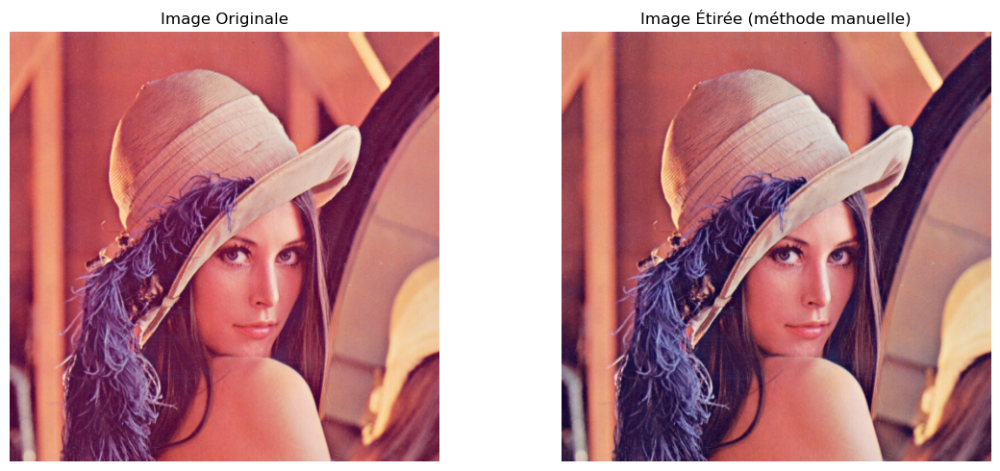

In [26]:
img = cv2.imread('Images_TD1\lena.png', cv2.IMREAD_UNCHANGED)
b, g, r = cv2.split(img)

def etirer_canal(canal):
    """Étire un canal entre 0 et 255"""
    Imin = np.min(canal)
    Imax = np.max(canal)
    print(f"Min: {Imin}, Max: {Imax}")
    canal_float = canal.astype(np.float32)
    canal_etire = (255 * (canal_float - Imin) / (Imax - Imin)).astype(np.uint8)
    return canal_etire

print("Canal Bleu:")
b_etire = etirer_canal(b)
print("Canal Vert:")
g_etire = etirer_canal(g)
print("Canal Rouge:")
r_etire = etirer_canal(r)

img_etiree = cv2.merge([b_etire, g_etire, r_etire])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Image Originale")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img_etiree, cv2.COLOR_BGR2RGB))
axes[1].set_title("Image Étirée (méthode manuelle)")
axes[1].axis('off')

plt.tight_layout()
plt.show()


## Exercice 2

### Normalisation d'histogramme

**Principe** : Transformer les fréquences absolues en **probabilités** (ou fréquences relatives)

**Formule** :
$$h_{norm}(i) = \frac{h(i)}{N}$$

où :
- $h(i)$ = nombre de pixels avec intensité $i$
- $N$ = nombre total de pixels (rows × cols)
- $h_{norm}(i)$ = probabilité d'avoir un pixel d'intensité $i$

**Propriétés** :
- $0 \leq h_{norm}(i) \leq 1$ pour tout $i$
- $\sum_{i=0}^{255} h_{norm}(i) = 1$ (pour histogramme normal)
- $h_{cumule\_norm}(255) = 1$ (pour histogramme cumulé normalisé)

**Utilité** :
- Facilite la comparaison entre images de tailles différentes
- Représente la distribution de probabilité des intensités
- Utilisé pour l'égalisation d'histogramme


Dimensions de l'image: 184 x 273 = 50232 pixels
Somme hist normalisé: 1.0000 (doit être ≈ 1)
Max hist cumulé normalisé: 1.0000 (doit être ≈ 1)
Plage hist normalisé: [0.000000, 0.023630]


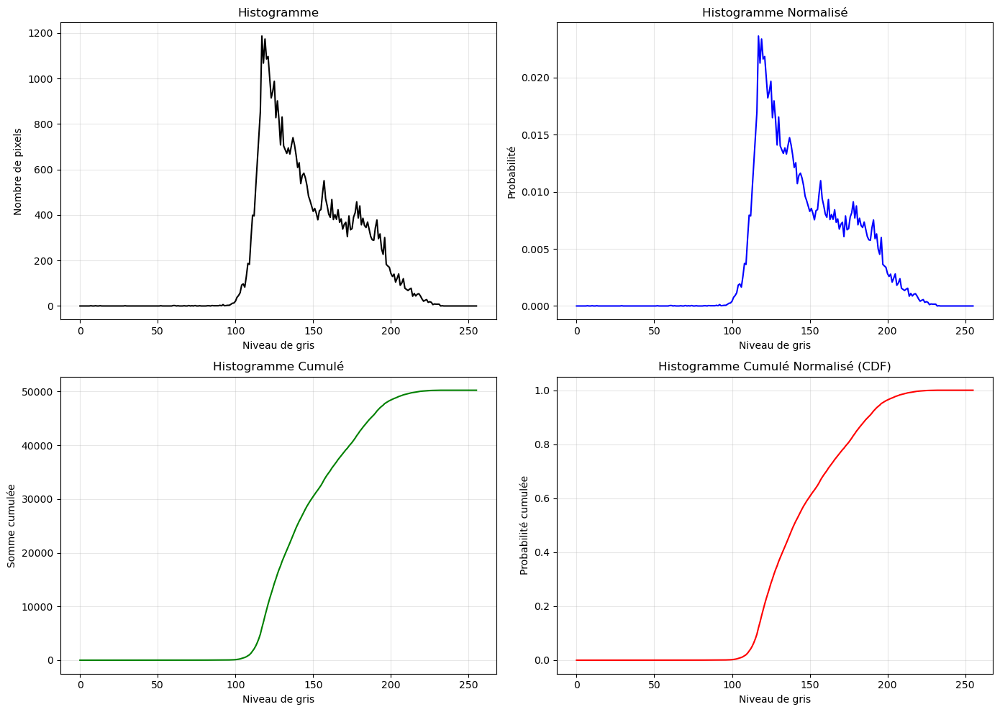

In [27]:
def histogrammeCumule(hist):
    """Calcule l'histogramme cumulé à partir d'un histogramme"""
    return np.cumsum(hist)

def histogrammeNormalise(hist, rows, cols):
    """
    Normalise un histogramme (normal ou cumulé) par le nombre total de pixels
    
    Paramètres:
    - hist: histogramme (tableau NumPy)
    - rows: nombre de lignes de l'image
    - cols: nombre de colonnes de l'image
    
    Retour:
    - Histogramme normalisé (valeurs entre 0 et 1)
    """
    nb_pixels = rows * cols
    return hist / nb_pixels

img = cv2.imread('sousexpo1.jpg', cv2.IMREAD_GRAYSCALE)
rows, cols = img.shape
hist = cv2.calcHist([img], [0], None, [256], [0, 256])
hist_cumule = histogrammeCumule(hist)
hist_normalise = histogrammeNormalise(hist, rows, cols)
hist_cumule_normalise = histogrammeNormalise(hist_cumule, rows, cols)

# Vérifications
print(f"Dimensions de l'image: {rows} x {cols} = {rows*cols} pixels")
print(f"Somme hist normalisé: {np.sum(hist_normalise):.4f} (doit être ≈ 1)")
print(f"Max hist cumulé normalisé: {np.max(hist_cumule_normalise):.4f} (doit être ≈ 1)")
print(f"Plage hist normalisé: [{np.min(hist_normalise):.6f}, {np.max(hist_normalise):.6f}]")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].plot(hist, color='black', linewidth=1.5)
axes[0, 0].set_title("Histogramme")
axes[0, 0].set_xlabel("Niveau de gris")
axes[0, 0].set_ylabel("Nombre de pixels")
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(hist_normalise, color='blue', linewidth=1.5)
axes[0, 1].set_title("Histogramme Normalisé")
axes[0, 1].set_xlabel("Niveau de gris")
axes[0, 1].set_ylabel("Probabilité")
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(hist_cumule, color='green', linewidth=1.5)
axes[1, 0].set_title("Histogramme Cumulé")
axes[1, 0].set_xlabel("Niveau de gris")
axes[1, 0].set_ylabel("Somme cumulée")
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(hist_cumule_normalise, color='red', linewidth=1.5)
axes[1, 1].set_title("Histogramme Cumulé Normalisé (CDF)")
axes[1, 1].set_xlabel("Niveau de gris")
axes[1, 1].set_ylabel("Probabilité cumulée")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


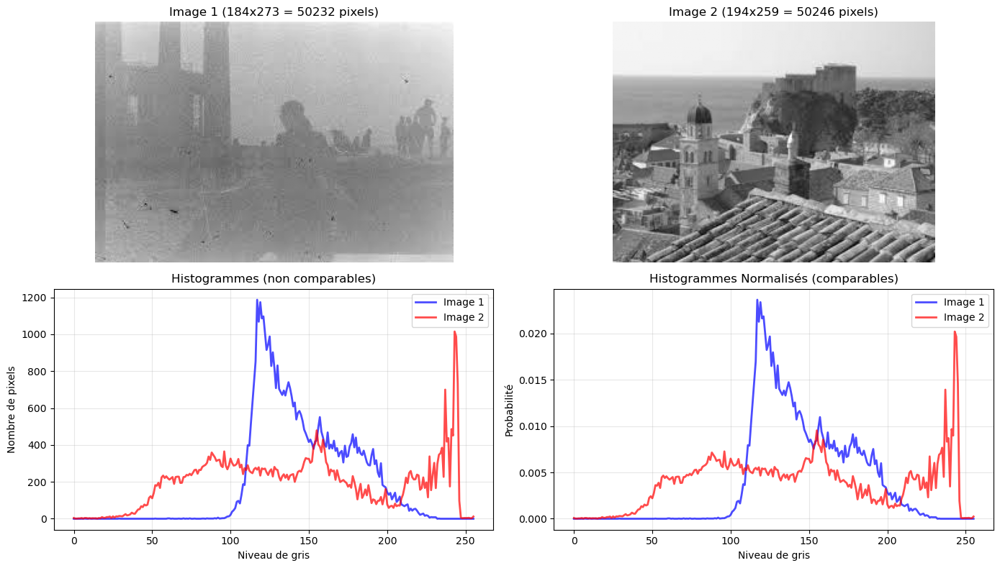

Image 1: 50232 pixels
Image 2: 50246 pixels

Les histogrammes normalisés permettent de comparer les distributions
indépendamment de la taille des images!


In [28]:
# Exemple pratique : Comparer deux images de tailles différentes
img1 = cv2.imread('sousexpo1.jpg', cv2.IMREAD_GRAYSCALE)
rows1, cols1 = img1.shape
hist1 = cv2.calcHist([img1], [0], None, [256], [0, 256])
hist1_norm = histogrammeNormalise(hist1, rows1, cols1)

img2 = cv2.imread('surexp.jpg', cv2.IMREAD_GRAYSCALE)
rows2, cols2 = img2.shape
hist2 = cv2.calcHist([img2], [0], None, [256], [0, 256])
hist2_norm = histogrammeNormalise(hist2, rows2, cols2)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].imshow(img1, cmap='gray')
axes[0, 0].set_title(f"Image 1 ({rows1}x{cols1} = {rows1*cols1} pixels)")
axes[0, 0].axis('off')

axes[0, 1].imshow(img2, cmap='gray')
axes[0, 1].set_title(f"Image 2 ({rows2}x{cols2} = {rows2*cols2} pixels)")
axes[0, 1].axis('off')

# Histogrammes non normalisés (échelles différentes!)
axes[1, 0].plot(hist1, color='blue', alpha=0.7, label='Image 1', linewidth=2)
axes[1, 0].plot(hist2, color='red', alpha=0.7, label='Image 2', linewidth=2)
axes[1, 0].set_title("Histogrammes (non comparables)")
axes[1, 0].set_xlabel("Niveau de gris")
axes[1, 0].set_ylabel("Nombre de pixels")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Histogrammes normalisés (comparables!)
axes[1, 1].plot(hist1_norm, color='blue', alpha=0.7, label='Image 1', linewidth=2)
axes[1, 1].plot(hist2_norm, color='red', alpha=0.7, label='Image 2', linewidth=2)
axes[1, 1].set_title("Histogrammes Normalisés (comparables)")
axes[1, 1].set_xlabel("Niveau de gris")
axes[1, 1].set_ylabel("Probabilité")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Image 1: {rows1*cols1} pixels")
print(f"Image 2: {rows2*cols2} pixels")
print(f"\nLes histogrammes normalisés permettent de comparer les distributions")
print(f"indépendamment de la taille des images!")


### Égalisation d'histogramme

**Principe** : Redistribuer les intensités des pixels pour obtenir un histogramme uniforme

**Objectif** : Améliorer le contraste en utilisant toute la plage de niveaux de gris

**Algorithme** :
1. Calculer l'histogramme $h(i)$
2. Calculer l'histogramme cumulé normalisé $H_{norm}(i)$
3. Appliquer la transformation : $I_{new} = 255 \times H_{norm}(I_{old})$

**Formule mathématique** :
$$g(i) = \left\lfloor 255 \times \frac{\sum_{j=0}^{i} h(j)}{N} \right\rfloor$$

où :
- $g(i)$ = nouvelle valeur de pixel
- $h(j)$ = nombre de pixels avec intensité $j$
- $N$ = nombre total de pixels

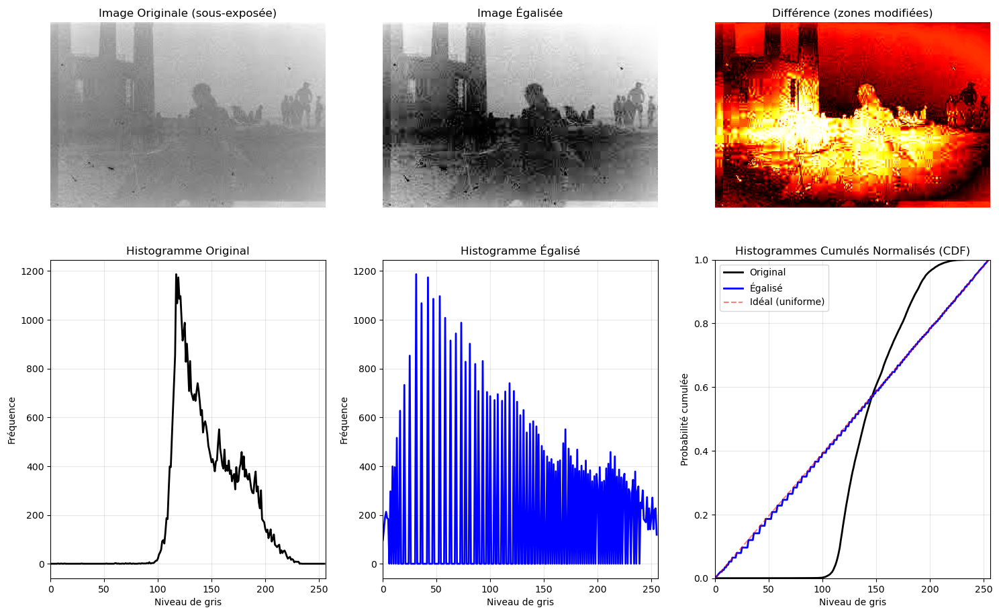

Statistiques :

Image originale:
  Min: 7, Max: 233
  Moyenne: 146.89, Écart-type: 27.47

Image égalisée:
  Min: 0, Max: 255
  Moyenne: 129.02, Écart-type: 73.03

L'égalisation améliore le contraste et utilise toute la plage [0, 255]


In [29]:
# Égalisation d'histogramme avec cv2.equalizeHist()
img = cv2.imread('sousexpo1.jpg', cv2.IMREAD_GRAYSCALE)
img_egalisee = cv2.equalizeHist(img)
hist_original = cv2.calcHist([img], [0], None, [256], [0, 256])
hist_egalisee = cv2.calcHist([img_egalisee], [0], None, [256], [0, 256])

fig = plt.figure(figsize=(15, 10))
ax1 = plt.subplot(2, 3, 1)
ax1.imshow(img, cmap='gray')
ax1.set_title("Image Originale (sous-exposée)")
ax1.axis('off')

ax2 = plt.subplot(2, 3, 2)
ax2.imshow(img_egalisee, cmap='gray')
ax2.set_title("Image Égalisée")
ax2.axis('off')

ax3 = plt.subplot(2, 3, 3)
difference = cv2.absdiff(img_egalisee, img)
ax3.imshow(difference, cmap='hot')
ax3.set_title("Différence (zones modifiées)")
ax3.axis('off')

ax4 = plt.subplot(2, 3, 4)
ax4.plot(hist_original, color='black', linewidth=2)
ax4.set_title("Histogramme Original")
ax4.set_xlabel("Niveau de gris")
ax4.set_ylabel("Fréquence")
ax4.grid(alpha=0.3)
ax4.set_xlim([0, 256])

ax5 = plt.subplot(2, 3, 5)
ax5.plot(hist_egalisee, color='blue', linewidth=2)
ax5.set_title("Histogramme Égalisé")
ax5.set_xlabel("Niveau de gris")
ax5.set_ylabel("Fréquence")
ax5.grid(alpha=0.3)
ax5.set_xlim([0, 256])

# Comparaison des histogrammes cumulés normalisés
ax6 = plt.subplot(2, 3, 6)
rows, cols = img.shape
hist_cumule_orig = histogrammeCumule(hist_original)
hist_cumule_egal = histogrammeCumule(hist_egalisee)
hist_cumule_orig_norm = histogrammeNormalise(hist_cumule_orig, rows, cols)
hist_cumule_egal_norm = histogrammeNormalise(hist_cumule_egal, rows, cols)

ax6.plot(hist_cumule_orig_norm, color='black', label='Original', linewidth=2)
ax6.plot(hist_cumule_egal_norm, color='blue', label='Égalisé', linewidth=2)
# Ligne diagonale idéale
ax6.plot([0, 255], [0, 1], 'r--', alpha=0.5, label='Idéal (uniforme)')
ax6.set_title("Histogrammes Cumulés Normalisés (CDF)")
ax6.set_xlabel("Niveau de gris")
ax6.set_ylabel("Probabilité cumulée")
ax6.legend()
ax6.grid(alpha=0.3)
ax6.set_xlim([0, 256])
ax6.set_ylim([0, 1])

plt.tight_layout()
plt.show()

# Statistiques
print("Statistiques :")
print(f"\nImage originale:")
print(f"  Min: {np.min(img)}, Max: {np.max(img)}")
print(f"  Moyenne: {np.mean(img):.2f}, Écart-type: {np.std(img):.2f}")
print(f"\nImage égalisée:")
print(f"  Min: {np.min(img_egalisee)}, Max: {np.max(img_egalisee)}")
print(f"  Moyenne: {np.mean(img_egalisee):.2f}, Écart-type: {np.std(img_egalisee):.2f}")
print(f"\nL'égalisation améliore le contraste et utilise toute la plage [0, 255]")


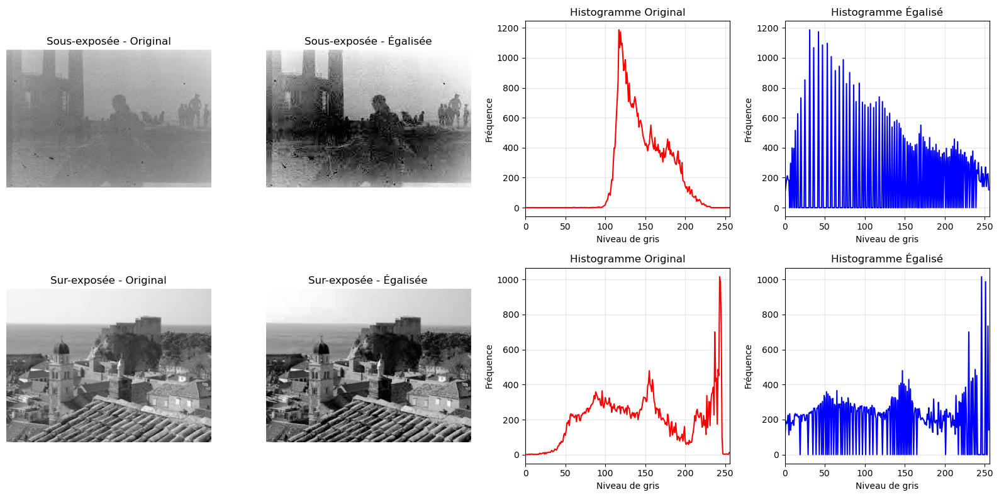

Observations:
- L'égalisation redistribue les intensités sur toute la plage [0, 255]
- L'histogramme égalisé est plus étalé et uniforme
- Le contraste est significativement amélioré


In [30]:
# Comparaison : Image sur-exposée vs sous-exposée

images = ['sousexpo1.jpg', 'surexp.jpg']
titles = ['Sous-exposée', 'Sur-exposée']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, (path, title) in enumerate(zip(images, titles)):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img_egalisee = cv2.equalizeHist(img)
    
    hist_orig = cv2.calcHist([img], [0], None, [256], [0, 256])
    hist_egal = cv2.calcHist([img_egalisee], [0], None, [256], [0, 256])

    axes[idx, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[idx, 0].set_title(f"{title} - Original")
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(img_egalisee, cmap='gray', vmin=0, vmax=255)
    axes[idx, 1].set_title(f"{title} - Égalisée")
    axes[idx, 1].axis('off')
    
    axes[idx, 2].plot(hist_orig, color='red', linewidth=1.5)
    axes[idx, 2].set_title("Histogramme Original")
    axes[idx, 2].set_xlabel("Niveau de gris")
    axes[idx, 2].set_ylabel("Fréquence")
    axes[idx, 2].grid(alpha=0.3)
    axes[idx, 2].set_xlim([0, 256])
    
    axes[idx, 3].plot(hist_egal, color='blue', linewidth=1.5)
    axes[idx, 3].set_title("Histogramme Égalisé")
    axes[idx, 3].set_xlabel("Niveau de gris")
    axes[idx, 3].set_ylabel("Fréquence")
    axes[idx, 3].grid(alpha=0.3)
    axes[idx, 3].set_xlim([0, 256])

plt.tight_layout()
plt.show()

print("Observations:")
print("- L'égalisation redistribue les intensités sur toute la plage [0, 255]")
print("- L'histogramme égalisé est plus étalé et uniforme")
print("- Le contraste est significativement amélioré")


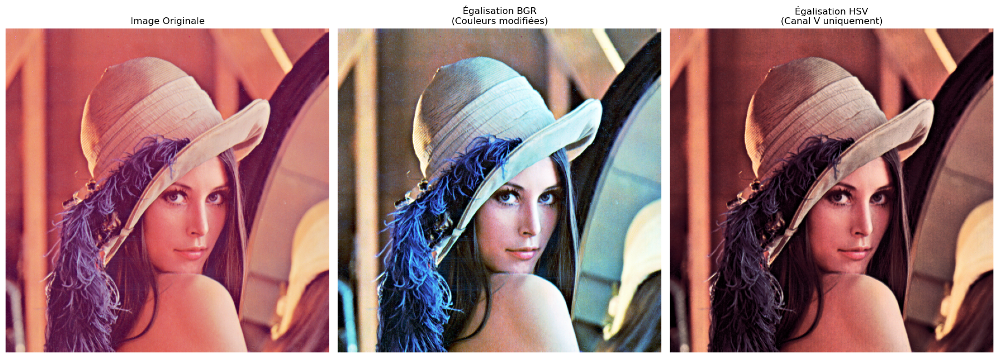

In [31]:
# Égalisation d'une image couleur - Comparaison des méthodes


img_color = cv2.imread('Images_TD1\lena.png')


# Méthode 1 : Égaliser chaque canal BGR séparément (MAUVAISE MÉTHODE)
b, g, r = cv2.split(img_color)
b_eq = cv2.equalizeHist(b)
g_eq = cv2.equalizeHist(g)
r_eq = cv2.equalizeHist(r)
img_bgr_eq = cv2.merge([b_eq, g_eq, r_eq])


# Méthode 2 : Égaliser seulement la luminosité (HSV) (BONNE MÉTHODE)
img_hsv = cv2.cvtColor(img_color, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(img_hsv)
v_eq = cv2.equalizeHist(v)
img_hsv_eq = cv2.merge([h, s, v_eq])
img_hsv_result = cv2.cvtColor(img_hsv_eq, cv2.COLOR_HSV2BGR)


# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(18, 7))


# Image originale
axes[0].imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
axes[0].set_title("Image Originale")
axes[0].axis('off')


# Méthode BGR (mauvaise)
axes[1].imshow(cv2.cvtColor(img_bgr_eq, cv2.COLOR_BGR2RGB))
axes[1].set_title("Égalisation BGR\n(Couleurs modifiées)")
axes[1].axis('off')


# Méthode HSV (bonne)
axes[2].imshow(cv2.cvtColor(img_hsv_result, cv2.COLOR_BGR2RGB))
axes[2].set_title("Égalisation HSV\n(Canal V uniquement)")
axes[2].axis('off')


plt.tight_layout()
plt.show()

### Question : Obtient-on un histogramme plat après égalisation ?

**Théorie** : L'égalisation d'histogramme vise à obtenir un histogramme **uniforme** (plat)

**Pratique** : On n'obtient **presque jamais** un histogramme parfaitement plat !

**Pourquoi ?**
1. Les valeurs de pixels sont discrètes (0-255, pas continues)
2. Plusieurs valeurs d'entrée peuvent être mappées à la même valeur de sortie
3. La distribution originale influence le résultat

**Résultat** : Un histogramme **plus étalé** et **mieux réparti**, mais pas parfaitement plat

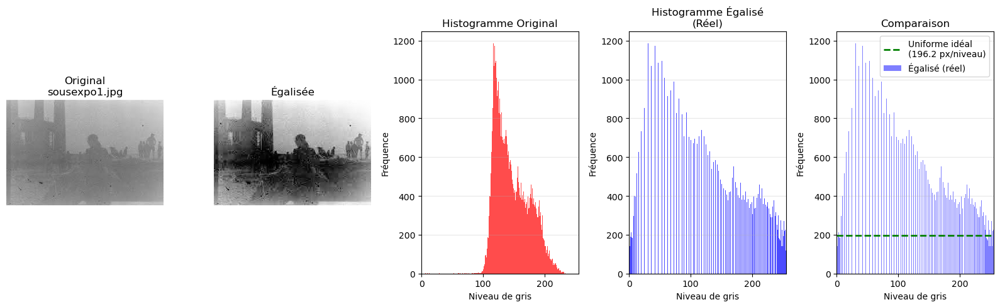


Analyse pour : sousexpo1.jpg
Nombre total de pixels : 50,232
Fréquence théorique uniforme : 196.22 pixels par niveau

Histogramme égalisé (réel) :
  - Moyenne : 196.22 pixels par niveau
  - Écart-type : 284.36
  - Coefficient de variation : 144.9%
  - Min : 0 pixels
  - Max : 1187 pixels

L'histogramme égalisé n'est PAS parfaitement plat !
   (CV = 144.9% ; un histogramme plat aurait CV = 0%)


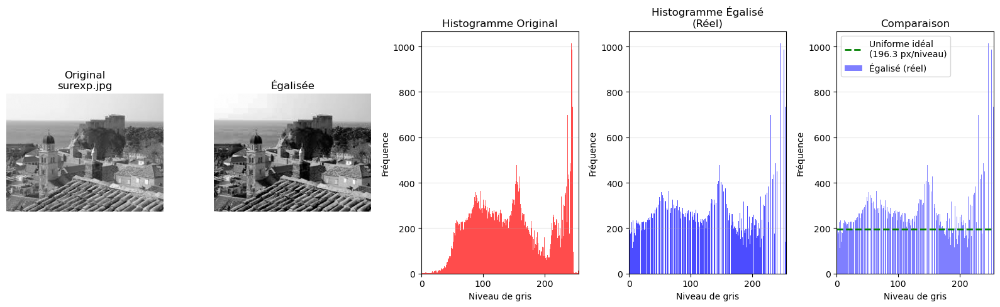


Analyse pour : surexp.jpg
Nombre total de pixels : 50,246
Fréquence théorique uniforme : 196.27 pixels par niveau

Histogramme égalisé (réel) :
  - Moyenne : 196.27 pixels par niveau
  - Écart-type : 152.03
  - Coefficient de variation : 77.5%
  - Min : 0 pixels
  - Max : 1015 pixels

L'histogramme égalisé n'est PAS parfaitement plat !
   (CV = 77.5% ; un histogramme plat aurait CV = 0%)


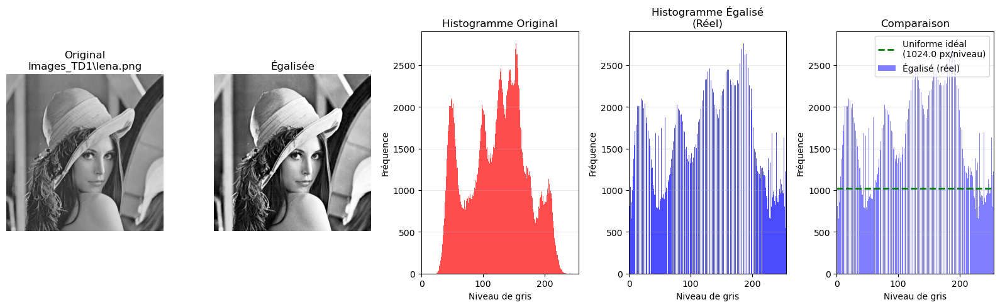


Analyse pour : Images_TD1\lena.png
Nombre total de pixels : 262,144
Fréquence théorique uniforme : 1024.00 pixels par niveau

Histogramme égalisé (réel) :
  - Moyenne : 1024.00 pixels par niveau
  - Écart-type : 834.50
  - Coefficient de variation : 81.5%
  - Min : 0 pixels
  - Max : 2765 pixels

L'histogramme égalisé n'est PAS parfaitement plat !
   (CV = 81.5% ; un histogramme plat aurait CV = 0%)

CONCLUSION GÉNÉRALE
L'égalisation AMÉLIORE la répartition des intensités
L'histogramme devient plus ÉTALÉ sur toute la plage [0, 255]
Mais l'histogramme n'est JAMAIS parfaitement PLAT/UNIFORME

Raisons :
  1. Discrétisation des valeurs (256 niveaux seulement)
  2. Mapping plusieurs→un (plusieurs valeurs d'entrée → même sortie)
  3. Structure de l'image originale


In [32]:
# Analyse détaillée : Histogrammes avant et après égalisation

# Tester avec différentes images
images_test = ['sousexpo1.jpg', 'surexp.jpg', 'Images_TD1\lena.png']

for img_path in images_test:
    # Charger l'image en niveaux de gris
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    
    # Égaliser
    img_egalisee = cv2.equalizeHist(img)
    
    # Calculer les histogrammes
    hist_original = cv2.calcHist([img], [0], None, [256], [0, 256])
    hist_egalisee = cv2.calcHist([img_egalisee], [0], None, [256], [0, 256])
    
    # Calculer les statistiques de l'histogramme égalisé
    hist_egal_flat = hist_egalisee.flatten()
    moyenne_hist = np.mean(hist_egal_flat)
    ecart_type_hist = np.std(hist_egal_flat)
    cv_hist = (ecart_type_hist / moyenne_hist) * 100  # Coefficient de variation en %
    
    # Histogramme parfaitement uniforme (théorique)
    nb_pixels = img.shape[0] * img.shape[1]
    hist_uniforme = np.full((256, 1), nb_pixels / 256)
    
    # Visualisation
    fig = plt.figure(figsize=(16, 5))
    
    # Image originale
    ax1 = plt.subplot(1, 5, 1)
    ax1.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax1.set_title(f"Original\n{img_path}")
    ax1.axis('off')
    
    # Image égalisée
    ax2 = plt.subplot(1, 5, 2)
    ax2.imshow(img_egalisee, cmap='gray', vmin=0, vmax=255)
    ax2.set_title("Égalisée")
    ax2.axis('off')
    
    # Histogramme original
    ax3 = plt.subplot(1, 5, 3)
    ax3.bar(range(256), hist_original.flatten(), color='red', alpha=0.7, width=1)
    ax3.set_title("Histogramme Original")
    ax3.set_xlabel("Niveau de gris")
    ax3.set_ylabel("Fréquence")
    ax3.set_xlim([0, 255])
    ax3.grid(alpha=0.3, axis='y')
    
    # Histogramme égalisé
    ax4 = plt.subplot(1, 5, 4)
    ax4.bar(range(256), hist_egalisee.flatten(), color='blue', alpha=0.7, width=1)
    ax4.set_title("Histogramme Égalisé\n(Réel)")
    ax4.set_xlabel("Niveau de gris")
    ax4.set_ylabel("Fréquence")
    ax4.set_xlim([0, 255])
    ax4.grid(alpha=0.3, axis='y')
    
    # Comparaison avec histogramme uniforme idéal
    ax5 = plt.subplot(1, 5, 5)
    ax5.bar(range(256), hist_egalisee.flatten(), color='blue', alpha=0.5, width=1, label='Égalisé (réel)')
    ax5.axhline(y=moyenne_hist, color='green', linestyle='--', linewidth=2, label=f'Uniforme idéal\n({nb_pixels/256:.1f} px/niveau)')
    ax5.set_title("Comparaison")
    ax5.set_xlabel("Niveau de gris")
    ax5.set_ylabel("Fréquence")
    ax5.set_xlim([0, 255])
    ax5.legend()
    ax5.grid(alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    # Analyse statistique
    print(f"\n{'='*70}")
    print(f"Analyse pour : {img_path}")
    print(f"{'='*70}")
    print(f"Nombre total de pixels : {nb_pixels:,}")
    print(f"Fréquence théorique uniforme : {nb_pixels/256:.2f} pixels par niveau")
    print(f"\nHistogramme égalisé (réel) :")
    print(f"  - Moyenne : {moyenne_hist:.2f} pixels par niveau")
    print(f"  - Écart-type : {ecart_type_hist:.2f}")
    print(f"  - Coefficient de variation : {cv_hist:.1f}%")
    print(f"  - Min : {np.min(hist_egal_flat):.0f} pixels")
    print(f"  - Max : {np.max(hist_egal_flat):.0f} pixels")
    print(f"\nL'histogramme égalisé n'est PAS parfaitement plat !")
    print(f"   (CV = {cv_hist:.1f}% ; un histogramme plat aurait CV = 0%)")
    
print("\n" + "="*70)
print("CONCLUSION GÉNÉRALE")
print("="*70)
print("L'égalisation AMÉLIORE la répartition des intensités")
print("L'histogramme devient plus ÉTALÉ sur toute la plage [0, 255]")
print("Mais l'histogramme n'est JAMAIS parfaitement PLAT/UNIFORME")
print("\nRaisons :")
print("  1. Discrétisation des valeurs (256 niveaux seulement)")
print("  2. Mapping plusieurs→un (plusieurs valeurs d'entrée → même sortie)")
print("  3. Structure de l'image originale")


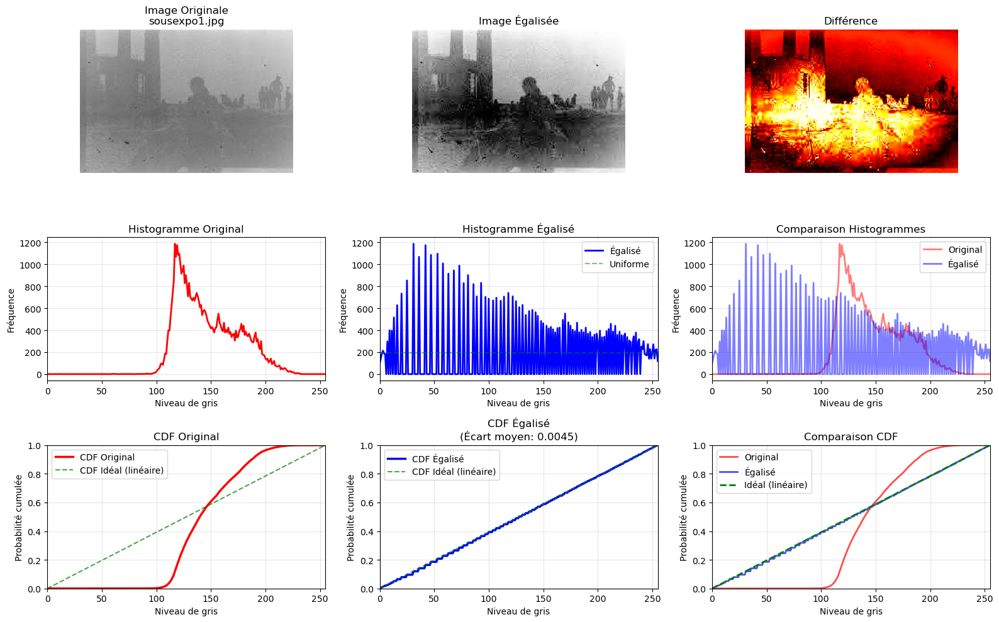


Analyse CDF pour : sousexpo1.jpg
CDF Originale :
  - Min : 0.0000
  - Max : 1.0000
  - Forme : Quasi-linéaire

CDF Égalisée :
  - Min : 0.0019
  - Max : 1.0000
  - Écart moyen par rapport à la linéarité : 0.0045
  - Écart maximum : 0.0215
CDF très proche de la linéarité !


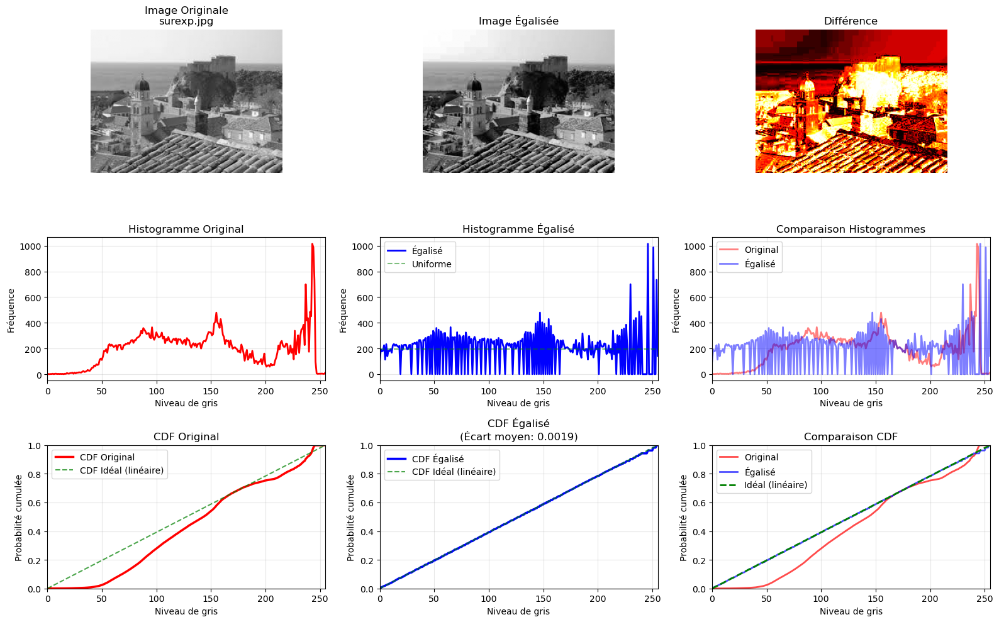


Analyse CDF pour : surexp.jpg
CDF Originale :
  - Min : 0.0001
  - Max : 1.0000
  - Forme : Quasi-linéaire

CDF Égalisée :
  - Min : 0.0020
  - Max : 1.0000
  - Écart moyen par rapport à la linéarité : 0.0019
  - Écart maximum : 0.0180
CDF très proche de la linéarité !


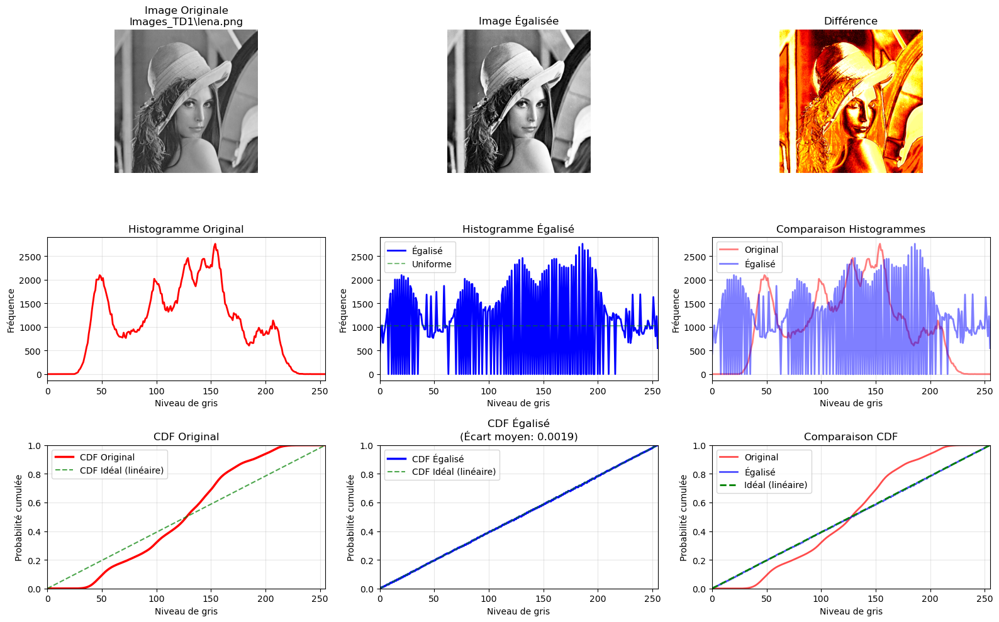


Analyse CDF pour : Images_TD1\lena.png
CDF Originale :
  - Min : 0.0000
  - Max : 1.0000
  - Forme : Quasi-linéaire

CDF Égalisée :
  - Min : 0.0016
  - Max : 1.0000
  - Écart moyen par rapport à la linéarité : 0.0019
  - Écart maximum : 0.0081
CDF très proche de la linéarité !

CONCLUSION GÉNÉRALE
L'égalisation transforme la CDF vers une forme PLUS LINÉAIRE
La CDF égalisée suit APPROXIMATIVEMENT la diagonale
Mais elle n'est JAMAIS parfaitement linéaire (forme en escalier)

Observations :
  • CDF original : Courbe avec pentes variables (zones concentrées)
  • CDF égalisé   : Courbe plus régulière, proche de y = x/255
  • CDF idéal     : Droite parfaite (impossible en pratique)


In [33]:
# Analyse des histogrammes cumulés normalisés (CDF) avant et après égalisation

# Tester avec plusieurs images
images_test = ['sousexpo1.jpg', 'surexp.jpg', 'Images_TD1\lena.png']

for img_path in images_test:
    # Charger l'image
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    rows, cols = img.shape
    nb_pixels = rows * cols
    
    # Égaliser
    img_egalisee = cv2.equalizeHist(img)
    
    # Calculer les histogrammes
    hist_original = cv2.calcHist([img], [0], None, [256], [0, 256])
    hist_egalisee = cv2.calcHist([img_egalisee], [0], None, [256], [0, 256])
    
    # Calculer les histogrammes cumulés
    hist_cumule_orig = histogrammeCumule(hist_original)
    hist_cumule_egal = histogrammeCumule(hist_egalisee)
    
    # Normaliser les histogrammes cumulés
    hist_cumule_orig_norm = histogrammeNormalise(hist_cumule_orig, rows, cols)
    hist_cumule_egal_norm = histogrammeNormalise(hist_cumule_egal, rows, cols)
    
    # CDF idéale (linéaire)
    cdf_ideal = np.linspace(0, 1, 256)
    
    # Calculer l'écart par rapport à la linéarité
    ecart_linearite = np.mean(np.abs(hist_cumule_egal_norm.flatten() - cdf_ideal))
    max_ecart = np.max(np.abs(hist_cumule_egal_norm.flatten() - cdf_ideal))
    
    # Visualisation
    fig = plt.figure(figsize=(16, 10))
    
    # === Ligne 1 : Images ===
    ax1 = plt.subplot(3, 3, 1)
    ax1.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax1.set_title(f"Image Originale\n{img_path}")
    ax1.axis('off')
    
    ax2 = plt.subplot(3, 3, 2)
    ax2.imshow(img_egalisee, cmap='gray', vmin=0, vmax=255)
    ax2.set_title("Image Égalisée")
    ax2.axis('off')
    
    ax3 = plt.subplot(3, 3, 3)
    difference = cv2.absdiff(img_egalisee, img)
    ax3.imshow(difference, cmap='hot')
    ax3.set_title("Différence")
    ax3.axis('off')
    
    # === Ligne 2 : Histogrammes ===
    ax4 = plt.subplot(3, 3, 4)
    ax4.plot(hist_original, color='red', linewidth=2, label='Original')
    ax4.set_title("Histogramme Original")
    ax4.set_xlabel("Niveau de gris")
    ax4.set_ylabel("Fréquence")
    ax4.grid(alpha=0.3)
    ax4.set_xlim([0, 255])
    
    ax5 = plt.subplot(3, 3, 5)
    ax5.plot(hist_egalisee, color='blue', linewidth=2, label='Égalisé')
    ax5.axhline(y=nb_pixels/256, color='green', linestyle='--', alpha=0.5, label='Uniforme')
    ax5.set_title("Histogramme Égalisé")
    ax5.set_xlabel("Niveau de gris")
    ax5.set_ylabel("Fréquence")
    ax5.legend()
    ax5.grid(alpha=0.3)
    ax5.set_xlim([0, 255])
    
    ax6 = plt.subplot(3, 3, 6)
    ax6.plot(hist_original, color='red', alpha=0.5, linewidth=2, label='Original')
    ax6.plot(hist_egalisee, color='blue', alpha=0.5, linewidth=2, label='Égalisé')
    ax6.set_title("Comparaison Histogrammes")
    ax6.set_xlabel("Niveau de gris")
    ax6.set_ylabel("Fréquence")
    ax6.legend()
    ax6.grid(alpha=0.3)
    ax6.set_xlim([0, 255])
    
    # === Ligne 3 : CDF (Histogrammes Cumulés Normalisés) ===
    ax7 = plt.subplot(3, 3, 7)
    ax7.plot(hist_cumule_orig_norm, color='red', linewidth=2.5, label='CDF Original')
    ax7.plot(cdf_ideal, 'g--', alpha=0.7, linewidth=1.5, label='CDF Idéal (linéaire)')
    ax7.set_title("CDF Original")
    ax7.set_xlabel("Niveau de gris")
    ax7.set_ylabel("Probabilité cumulée")
    ax7.legend()
    ax7.grid(alpha=0.3)
    ax7.set_xlim([0, 255])
    ax7.set_ylim([0, 1])
    
    ax8 = plt.subplot(3, 3, 8)
    ax8.plot(hist_cumule_egal_norm, color='blue', linewidth=2.5, label='CDF Égalisé')
    ax8.plot(cdf_ideal, 'g--', alpha=0.7, linewidth=1.5, label='CDF Idéal (linéaire)')
    ax8.set_title(f"CDF Égalisé\n(Écart moyen: {ecart_linearite:.4f})")
    ax8.set_xlabel("Niveau de gris")
    ax8.set_ylabel("Probabilité cumulée")
    ax8.legend()
    ax8.grid(alpha=0.3)
    ax8.set_xlim([0, 255])
    ax8.set_ylim([0, 1])
    
    ax9 = plt.subplot(3, 3, 9)
    ax9.plot(hist_cumule_orig_norm, color='red', linewidth=2, alpha=0.7, label='Original')
    ax9.plot(hist_cumule_egal_norm, color='blue', linewidth=2, alpha=0.7, label='Égalisé')
    ax9.plot(cdf_ideal, 'g--', linewidth=2, label='Idéal (linéaire)')
    ax9.set_title("Comparaison CDF")
    ax9.set_xlabel("Niveau de gris")
    ax9.set_ylabel("Probabilité cumulée")
    ax9.legend()
    ax9.grid(alpha=0.3)
    ax9.set_xlim([0, 255])
    ax9.set_ylim([0, 1])
    
    plt.tight_layout()
    plt.show()
    
    # Analyse statistique
    print(f"\n{'='*70}")
    print(f"Analyse CDF pour : {img_path}")
    print(f"{'='*70}")
    print(f"CDF Originale :")
    print(f"  - Min : {np.min(hist_cumule_orig_norm):.4f}")
    print(f"  - Max : {np.max(hist_cumule_orig_norm):.4f}")
    print(f"  - Forme : {'Non linéaire (concentrée sur certaines zones)' if ecart_linearite > 0.1 else 'Quasi-linéaire'}")
    print(f"\nCDF Égalisée :")
    print(f"  - Min : {np.min(hist_cumule_egal_norm):.4f}")
    print(f"  - Max : {np.max(hist_cumule_egal_norm):.4f}")
    print(f"  - Écart moyen par rapport à la linéarité : {ecart_linearite:.4f}")
    print(f"  - Écart maximum : {max_ecart:.4f}")
    
    if ecart_linearite < 0.05:
        print(f"CDF très proche de la linéarité !")
    elif ecart_linearite < 0.15:
        print(f"CDF quasi-linéaire")
    else:
        print(f"CDF s'éloigne de la linéarité")
    
print("\n" + "="*70)
print("CONCLUSION GÉNÉRALE")
print("="*70)
print("L'égalisation transforme la CDF vers une forme PLUS LINÉAIRE")
print("La CDF égalisée suit APPROXIMATIVEMENT la diagonale")
print("Mais elle n'est JAMAIS parfaitement linéaire (forme en escalier)")
print("\nObservations :")
print("  • CDF original : Courbe avec pentes variables (zones concentrées)")
print("  • CDF égalisé   : Courbe plus régulière, proche de y = x/255")
print("  • CDF idéal     : Droite parfaite (impossible en pratique)")


ANALYSE QUANTITATIVE DE LA LINÉARITÉ DES CDF

sousexpo1.jpg
────────────────────────────────────────────────────────────────────────────────
Métrique             | CDF Original         | CDF Égalisé          | Amélioration
────────────────────────────────────────────────────────────────────────────────
MAE                  |             0.1636 |             0.0045 |   97.3%
RMSE                 |             0.1991 |             0.0063 |   96.8%
Corrélation          |             0.9406 |             0.9999 | +     
R²                   |             0.7847 |             0.9995 | +     

  Verdict : Excellente linéarité (R² = 0.9995)

surexp.jpg
────────────────────────────────────────────────────────────────────────────────
Métrique             | CDF Original         | CDF Égalisé          | Amélioration
────────────────────────────────────────────────────────────────────────────────
MAE                  |             0.0746 |             0.0019 |   97.5%
RMSE                 |       

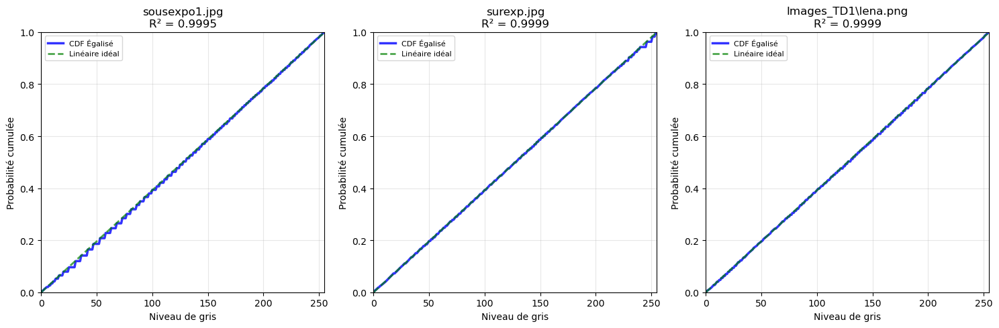


CONCLUSION
La CDF après égalisation est SIGNIFICATIVEMENT plus linéaire
Le R² proche de 1 indique une très bonne approximation de la linéarité
Mais elle n'est JAMAIS parfaitement linéaire (R² < 1)

Forme obtenue : Fonction en ESCALIER qui suit la diagonale
   (Plus de pixels → marches plus fines → plus proche de la linéarité)


In [34]:
# Comparaison quantitative : Mesure de la linéarité

def calculer_linearite(cdf_norm):
    """
    Calcule différentes métriques pour mesurer la linéarité d'une CDF
    """
    cdf_ideal = np.linspace(0, 1, 256)
    cdf_flat = cdf_norm.flatten()
    
    # Erreur absolue moyenne (MAE)
    mae = np.mean(np.abs(cdf_flat - cdf_ideal))
    
    # Erreur quadratique moyenne (RMSE)
    rmse = np.sqrt(np.mean((cdf_flat - cdf_ideal)**2))
    
    # Coefficient de corrélation
    correlation = np.corrcoef(cdf_flat, cdf_ideal)[0, 1]
    
    # Coefficient R² (coefficient de détermination)
    ss_res = np.sum((cdf_flat - cdf_ideal)**2)
    ss_tot = np.sum((cdf_flat - np.mean(cdf_flat))**2)
    r_squared = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0
    
    return {
        'MAE': mae,
        'RMSE': rmse,
        'Correlation': correlation,
        'R²': r_squared
    }

# Test sur plusieurs images
print("="*80)
print("ANALYSE QUANTITATIVE DE LA LINÉARITÉ DES CDF")
print("="*80)

images_test = ['sousexpo1.jpg', 'surexp.jpg', 'Images_TD1\lena.png']
resultats = []

for img_path in images_test:
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img_egal = cv2.equalizeHist(img)
    
    rows, cols = img.shape
    
    # CDF originale
    hist_orig = cv2.calcHist([img], [0], None, [256], [0, 256])
    cdf_orig = histogrammeCumule(hist_orig)
    cdf_orig_norm = histogrammeNormalise(cdf_orig, rows, cols)
    
    # CDF égalisée
    hist_egal = cv2.calcHist([img_egal], [0], None, [256], [0, 256])
    cdf_egal = histogrammeCumule(hist_egal)
    cdf_egal_norm = histogrammeNormalise(cdf_egal, rows, cols)
    
    # Calculer les métriques
    metrics_orig = calculer_linearite(cdf_orig_norm)
    metrics_egal = calculer_linearite(cdf_egal_norm)
    
    resultats.append({
        'image': img_path,
        'orig': metrics_orig,
        'egal': metrics_egal
    })
    
    print(f"\n{img_path}")
    print(f"{'─'*80}")
    print(f"{'Métrique':<20} | {'CDF Original':<20} | {'CDF Égalisé':<20} | {'Amélioration'}")
    print(f"{'─'*80}")
    print(f"{'MAE':<20} | {metrics_orig['MAE']:>18.4f} | {metrics_egal['MAE']:>18.4f} | {((metrics_orig['MAE']-metrics_egal['MAE'])/metrics_orig['MAE']*100):>6.1f}%")
    print(f"{'RMSE':<20} | {metrics_orig['RMSE']:>18.4f} | {metrics_egal['RMSE']:>18.4f} | {((metrics_orig['RMSE']-metrics_egal['RMSE'])/metrics_orig['RMSE']*100):>6.1f}%")
    print(f"{'Corrélation':<20} | {metrics_orig['Correlation']:>18.4f} | {metrics_egal['Correlation']:>18.4f} | {'+':<6}")
    print(f"{'R²':<20} | {metrics_orig['R²']:>18.4f} | {metrics_egal['R²']:>18.4f} | {'+':<6}")
    
    # Interprétation
    if metrics_egal['R²'] > 0.95:
        verdict = "Excellente linéarité"
    elif metrics_egal['R²'] > 0.90:
        verdict = "Très bonne linéarité"
    elif metrics_egal['R²'] > 0.80:
        verdict = "Bonne linéarité"
    else:
        verdict = "Linéarité modérée"
    
    print(f"\n  Verdict : {verdict} (R² = {metrics_egal['R²']:.4f})")

# Visualisation comparative
fig, axes = plt.subplots(1, len(images_test), figsize=(15, 5))

for idx, (img_path, result) in enumerate(zip(images_test, resultats)):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img_egal = cv2.equalizeHist(img)
    rows, cols = img.shape
    
    hist_egal = cv2.calcHist([img_egal], [0], None, [256], [0, 256])
    cdf_egal = histogrammeCumule(hist_egal)
    cdf_egal_norm = histogrammeNormalise(cdf_egal, rows, cols)
    
    cdf_ideal = np.linspace(0, 1, 256)
    
    axes[idx].plot(cdf_egal_norm, 'b-', linewidth=2.5, label='CDF Égalisé', alpha=0.8)
    axes[idx].plot(cdf_ideal, 'g--', linewidth=2, label='Linéaire idéal', alpha=0.7)
    axes[idx].set_title(f"{img_path}\nR² = {result['egal']['R²']:.4f}")
    axes[idx].set_xlabel("Niveau de gris")
    axes[idx].set_ylabel("Probabilité cumulée")
    axes[idx].legend(fontsize=8)
    axes[idx].grid(alpha=0.3)
    axes[idx].set_xlim([0, 255])
    axes[idx].set_ylim([0, 1])

plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("CONCLUSION")
print("="*80)
print("La CDF après égalisation est SIGNIFICATIVEMENT plus linéaire")
print("Le R² proche de 1 indique une très bonne approximation de la linéarité")
print("Mais elle n'est JAMAIS parfaitement linéaire (R² < 1)")
print("\nForme obtenue : Fonction en ESCALIER qui suit la diagonale")
print("   (Plus de pixels → marches plus fines → plus proche de la linéarité)")


## Exercice 3

Image originale: 512×512 pixels
Image zoomée: 1024×1024 pixels
Facteur de zoom réel: 2.0x


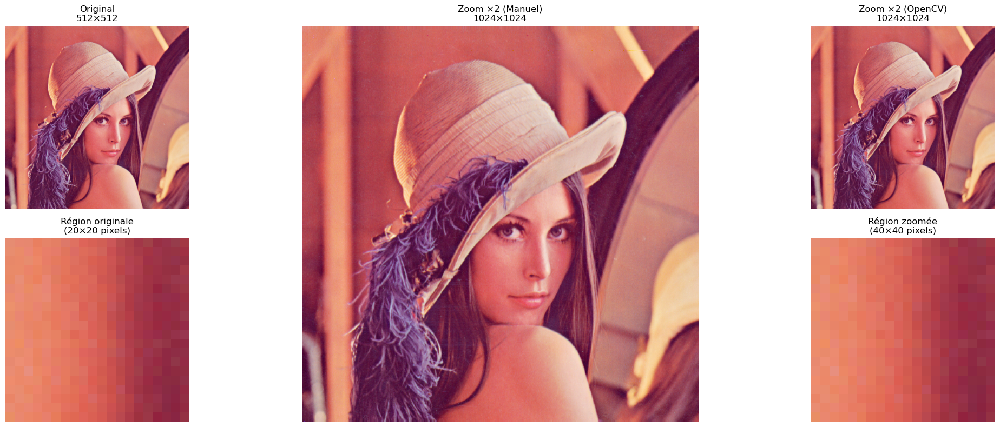

Zoom ×2: Manuel vs OpenCV → Identiques


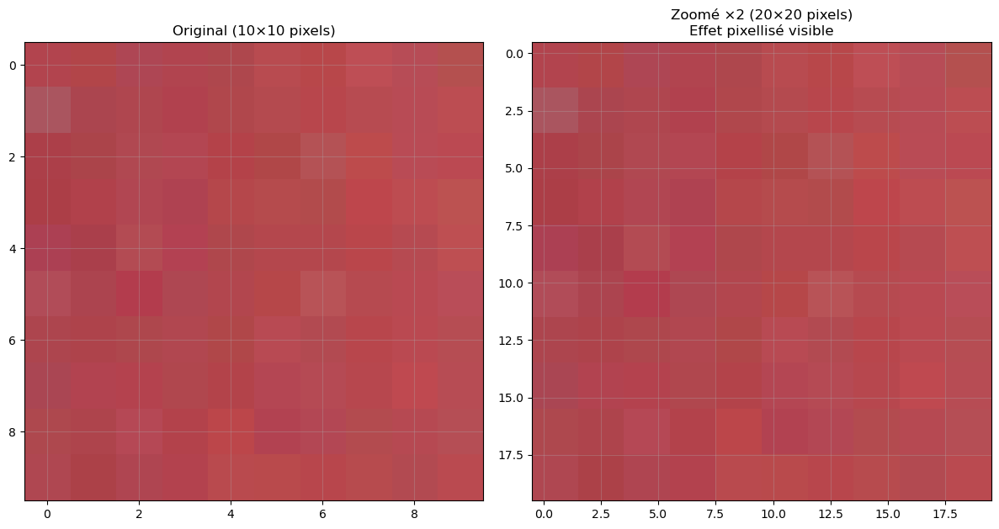

In [37]:
import cv2,matplotlib.pyplot as plt,numpy as np
def zoom(path, facteur=2):
    img = cv2.imread(path)
    if img is None:
        print(f"Erreur : impossible de charger {path}")
        return None
    
    hauteur, largeur, canaux = img.shape
    
    # Nouvelles dimensions
    nouvelle_hauteur = hauteur * facteur
    nouvelle_largeur = largeur * facteur
    
    # Créer l'image zoomée
    img_zoomee = np.zeros((nouvelle_hauteur, nouvelle_largeur, canaux), dtype=np.uint8)
    
    # Pour chaque pixel de l'image originale
    for i in range(hauteur):
        for j in range(largeur):
            # Récupérer la couleur du pixel original
            couleur_pixel = img[i, j]
            
            # Copier cette couleur sur un bloc facteur×facteur
            for di in range(facteur):
                for dj in range(facteur):
                    img_zoomee[i * facteur + di, j * facteur + dj] = couleur_pixel
    
    return img, img_zoomee

def demo_zoom():
    img_originale = cv2.imread('Images_TD1\lena.png')
    if img_originale is None:
        print("Erreur : fichier lena.png non trouvé")
        return
    
    # Zoom manuel ×2
    img_orig, img_zoom_manuel = zoom('Images_TD1\lena.png', 2)
    
    # Zoom OpenCV ×2 pour comparaison
    nouvelle_taille = (img_originale.shape[1] * 2, img_originale.shape[0] * 2)
    img_zoom_opencv = cv2.resize(img_originale, nouvelle_taille, interpolation=cv2.INTER_NEAREST)
    
    # Afficher les informations sur les tailles
    print(f"Image originale: {img_originale.shape[1]}×{img_originale.shape[0]} pixels")
    print(f"Image zoomée: {img_zoom_manuel.shape[1]}×{img_zoom_manuel.shape[0]} pixels")
    print(f"Facteur de zoom réel: {img_zoom_manuel.shape[0]/img_originale.shape[0]:.1f}x")
    
    # Créer une figure avec des sous-parcelles de tailles différentes
    fig = plt.figure(figsize=(20, 8))
    
    # Image originale (plus petite)
    ax1 = plt.subplot2grid((2, 4), (0, 0), colspan=1, rowspan=1)
    ax1.imshow(cv2.cvtColor(img_originale, cv2.COLOR_BGR2RGB))
    ax1.set_title(f"Original\n{img_originale.shape[1]}×{img_originale.shape[0]}")
    ax1.axis('off')
    
    # Zoom manuel (plus grande)
    ax2 = plt.subplot2grid((2, 4), (0, 1), colspan=2, rowspan=2)
    ax2.imshow(cv2.cvtColor(img_zoom_manuel, cv2.COLOR_BGR2RGB))
    ax2.set_title(f"Zoom ×2 (Manuel)\n{img_zoom_manuel.shape[1]}×{img_zoom_manuel.shape[0]}")
    ax2.axis('off')
    
    # Zoom OpenCV (plus grande)
    ax3 = plt.subplot2grid((2, 4), (0, 3), colspan=1, rowspan=1)
    ax3.imshow(cv2.cvtColor(img_zoom_opencv, cv2.COLOR_BGR2RGB))
    ax3.set_title(f"Zoom ×2 (OpenCV)\n{img_zoom_opencv.shape[1]}×{img_zoom_opencv.shape[0]}")
    ax3.axis('off')
    
    # Zoom sur une région pour voir les pixels
    # Prendre une petite région de l'image originale
    region_orig = img_originale[50:70, 50:70]  # 20x20 pixels
    region_zoom = img_zoom_manuel[100:140, 100:140]  # 40x40 pixels (correspondant)
    
    ax4 = plt.subplot2grid((2, 4), (1, 0), colspan=1, rowspan=1)
    ax4.imshow(cv2.cvtColor(region_orig, cv2.COLOR_BGR2RGB), interpolation='nearest')
    ax4.set_title("Région originale\n(20×20 pixels)")
    ax4.axis('off')
    
    ax5 = plt.subplot2grid((2, 4), (1, 3), colspan=1, rowspan=1)
    ax5.imshow(cv2.cvtColor(region_zoom, cv2.COLOR_BGR2RGB), interpolation='nearest')
    ax5.set_title("Région zoomée\n(40×40 pixels)")
    ax5.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Vérifier si les résultats sont identiques
    sont_identiques = np.array_equal(img_zoom_manuel, img_zoom_opencv)
    print(f"Zoom ×2: Manuel vs OpenCV → {'Identiques' if sont_identiques else 'Différents'}")
    
    # Démonstration de l'effet pixellisé
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
    # Région très petite de l'original
    petit_region = img_originale[100:110, 100:110]  # 10x10 pixels
    grand_region = img_zoom_manuel[200:220, 200:220]  # 20x20 pixels
    
    axes[0].imshow(cv2.cvtColor(petit_region, cv2.COLOR_BGR2RGB), interpolation='nearest')
    axes[0].set_title("Original (10×10 pixels)")
    axes[0].grid(True, alpha=0.3)
    
    axes[1].imshow(cv2.cvtColor(grand_region, cv2.COLOR_BGR2RGB), interpolation='nearest')
    axes[1].set_title("Zoomé ×2 (20×20 pixels)\nEffet pixellisé visible")
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


demo_zoom()

### 3. Méthode du Max-Pooling

Max-pooling avec blocs 8x8
Original: (512, 512)  ->  Pool: (64, 64)


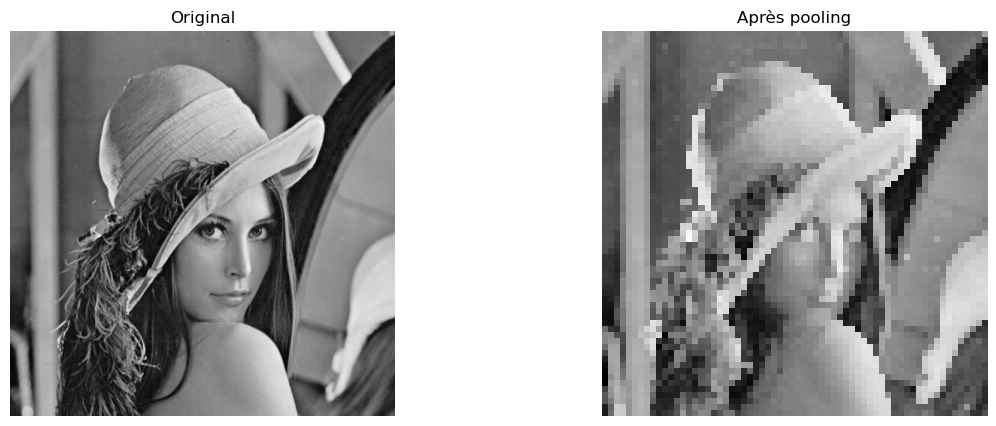

In [36]:
def max_pooling(path='Images_TD1\lena.png'):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    try:
        bloc = int(input("Entrez la taille du bloc (ex: 2 pour 2x2) : ").strip())
        if bloc < 2:
            print("Valeur < 2 → utilisation de 2 par défaut.")
            bloc = 2
    except:
        print("Entrée invalide → utilisation de 2 par défaut.")
        bloc = 2

    hauteur, largeur = img.shape
    nouvelle_hauteur = hauteur // bloc
    nouvelle_largeur = largeur // bloc
    img_reduite = np.zeros((nouvelle_hauteur, nouvelle_largeur), dtype=np.uint8)

    for i in range(0, nouvelle_hauteur):
        for j in range(0, nouvelle_largeur):
            sous_bloc = img[i*bloc:(i+1)*bloc, j*bloc:(j+1)*bloc]
            img_reduite[i, j] = np.max(sous_bloc)

    print(f"Max-pooling avec blocs {bloc}x{bloc}")
    return img, img_reduite

img_orig, img_pooled = max_pooling('Images_TD1\lena.png')
if img_orig is not None:
    print(f"Original: {img_orig.shape[::-1]}  ->  Pool: {img_pooled.shape[::-1]}")
    fig, axes = plt.subplots(1, 2, figsize=(14,5))
    axes[0].imshow(img_orig, cmap='gray'); axes[0].set_title("Original"); axes[0].axis('off')
    axes[1].imshow(img_pooled, cmap='gray'); axes[1].set_title("Après pooling"); axes[1].axis('off')
    # Agrandissement pour comparer (nearest)
    #up = cv2.resize(img_pooled, (img_orig.shape[1], img_orig.shape[0]), interpolation=cv2.INTER_NEAREST)
    #axes[2].imshow(up, cmap='gray'); axes[2].set_title("Pooling (remis à taille)"); axes[2].axis('off')
    #plt.tight_layout() 
    plt.show()